In [1]:
import sys
sys.path.insert(0, "..")  # repository root, so `import km5c` works
from km5c.transects import great_circle_distance, project_points_to_transect
from km5c.paths import FIG_DIR, GEBCO_PATH
from km5c.proxies import comparison_tables

proxy = comparison_tables()
PLIOMIP2_d18O_comparison_table = proxy.PLIOMIP2_d18O_comparison_table

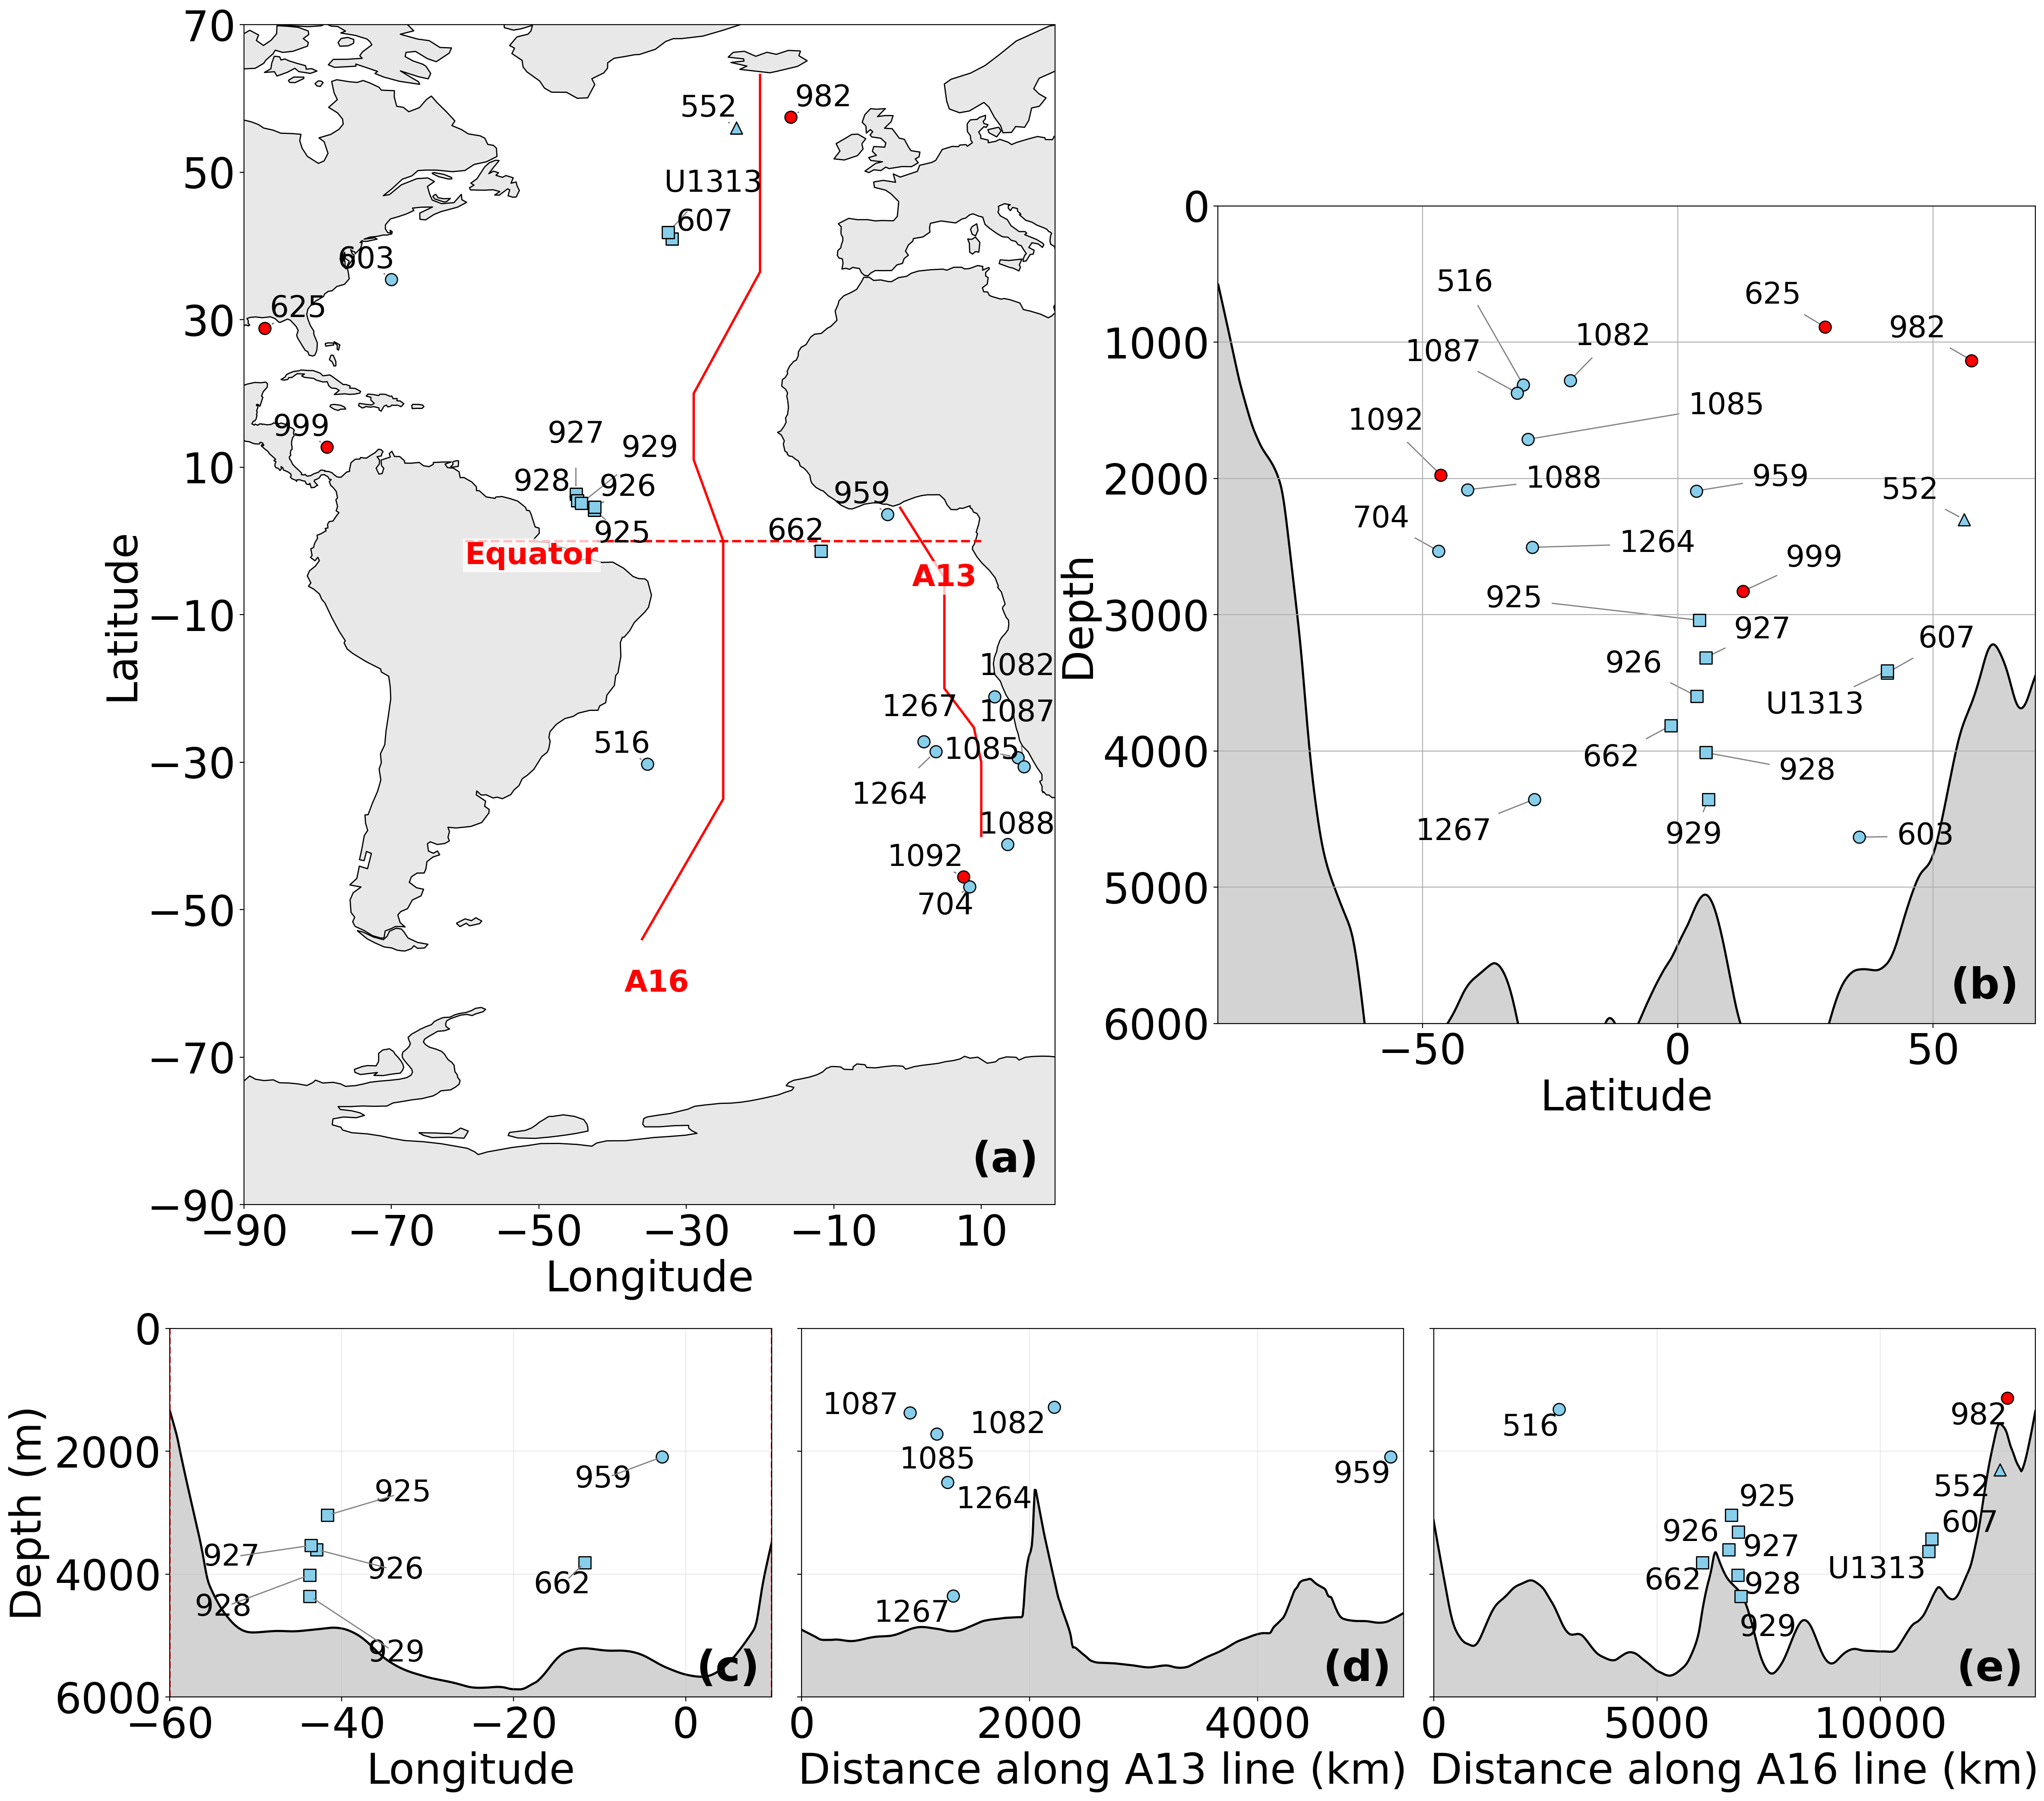

In [2]:
import math
from collections import defaultdict

import matplotlib as mpl
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import pandas as pd
import xarray as xr
from adjustText import adjust_text
from statsmodels.nonparametric.smoothers_lowess import lowess

mpl.rcParams.update(mpl.rcParamsDefault)
plt.rcdefaults()
mpl.rcParams.update({
    "font.size": 35,
    "axes.labelsize": 35,
    "xtick.labelsize": 35,
    "ytick.labelsize": 35,
})

SITE_LABEL_FONTSIZE = 25
PANEL_LABEL_FONTSIZE = 35

LABEL_ARROWPROPS = dict(arrowstyle="->", color="grey", lw=1, shrinkA=8, shrinkB=4)
MAP_LABEL_ARROWPROPS = dict(arrowstyle="->", color="grey", lw=1, shrinkA=16, shrinkB=6)

# --- Transect geometry ---
A13_line_lon = [10, 10, 9, 5, 5, -1]
A13_line_lat = [-40, -30, -25.3, -20, -5, 4.5]

A16_line_lon = [-36, -25, -25, -29, -29, -20, -20]
A16_line_lat = [-54, -35, 0, 11, 20, 36.5, 63.2]

box_latitudes = [-10.5, 10.5, 10.5, -10.5, -10.5]
box_longitudes = [-60, -60, 10, 10, -60]
box_lon_min, box_lon_max = min(box_longitudes), max(box_longitudes)
box_lat_min, box_lat_max = min(box_latitudes), max(box_latitudes)

# --- Bathymetry ---
bathymetry_file_path = GEBCO_PATH
bathymetry = xr.open_dataset(bathymetry_file_path, chunks={"lat": 500, "lon": 500})

if float(bathymetry["lon"].max()) > 180:
    bathymetry = bathymetry.assign_coords(lon=(((bathymetry["lon"] + 180) % 360) - 180))
    bathymetry = bathymetry.sortby("lon")
if float(bathymetry["lat"].values[0]) > float(bathymetry["lat"].values[-1]):
    bathymetry = bathymetry.sortby("lat")

lat_mask = (bathymetry["lat"] >= -90) & (bathymetry["lat"] <= 90)
lon_mask = (bathymetry["lon"] >= -100) & (bathymetry["lon"] <= 45)
bathymetry_atl = bathymetry.isel(lat=lat_mask, lon=lon_mask)
bathymetry_downsampled = bathymetry_atl.coarsen(lat=20, lon=20, boundary="trim").mean()
bathymetry_elev_ds = bathymetry_downsampled

bathymetry_lat = np.asarray(bathymetry_downsampled["lat"].values, dtype=float)
bathymetry_lon = np.asarray(bathymetry_downsampled["lon"].values, dtype=float)
bathymetry_depth = bathymetry_downsampled["elevation"].astype(np.float32).load().values
bathymetry.close()

bathymetry_lon_wrapped = ((bathymetry_lon + 180) % 360) - 180
lon_order = np.argsort(bathymetry_lon_wrapped)
bathymetry_lon_wrapped = bathymetry_lon_wrapped[lon_order]
bathymetry_depth = bathymetry_depth[:, lon_order]

# Atlantic lon subset already applied; mask land without building a full global mesh
ocean_depth = np.where(bathymetry_depth > 0, np.nan, bathymetry_depth)
compressed_bathymetry_positive_full = np.abs(np.nanmin(ocean_depth, axis=1))

x_full = np.arange(len(compressed_bathymetry_positive_full), dtype=float)
smoothed_full = lowess(
    np.asarray(compressed_bathymetry_positive_full, dtype=float),
    x_full,
    frac=0.05,
    return_sorted=False,
)

transect_depth_max = 6000

box_band = (bathymetry_lat >= box_lat_min) & (bathymetry_lat <= box_lat_max)
box_bathy_grid = bathymetry_depth[box_band, :]
box_bathy_profile = np.nanmin(box_bathy_grid, axis=0)
box_bathy_profile = np.where(np.isfinite(box_bathy_profile), np.abs(box_bathy_profile), np.nan)
box_valid = np.isfinite(box_bathy_profile)
if box_valid.sum() >= 2:
    box_bathy_smooth = lowess(
        box_bathy_profile[box_valid],
        bathymetry_lon_wrapped[box_valid],
        frac=0.05,
        return_sorted=False,
    )
    box_bathy_line = np.full_like(box_bathy_profile, np.nan, dtype=float)
    box_bathy_line[box_valid] = box_bathy_smooth
else:
    box_bathy_line = box_bathy_profile


def cumulative_distance_km(lon_values, lat_values):
    lon_values = np.asarray(lon_values, dtype=float)
    lat_values = np.asarray(lat_values, dtype=float)
    distances = [0.0]
    for index in range(1, len(lon_values)):
        distances.append(
            distances[-1]
            + great_circle_distance(
                lat_values[index - 1],
                lon_values[index - 1],
                lat_values[index],
                lon_values[index],
            )
        )
    return np.asarray(distances, dtype=float)


def polyline_midpoint(lon_values, lat_values):
    segment_distance = cumulative_distance_km(lon_values, lat_values)
    half_distance = 0.5 * segment_distance[-1]
    return (
        np.interp(half_distance, segment_distance, lon_values),
        np.interp(half_distance, segment_distance, lat_values),
    )


def resample_polyline(lon_values, lat_values, samples=400):
    lon_values = np.asarray(lon_values, dtype=float)
    lat_values = np.asarray(lat_values, dtype=float)
    segment_distance = cumulative_distance_km(lon_values, lat_values)
    sample_distance = np.linspace(segment_distance[0], segment_distance[-1], samples)
    sample_lon = np.interp(sample_distance, segment_distance, lon_values)
    sample_lat = np.interp(sample_distance, segment_distance, lat_values)
    return sample_lon, sample_lat, sample_distance


def wrap_longitude_like_dataset(lon_values):
    lon_values = np.asarray(lon_values, dtype=float)
    return ((lon_values + 180) % 360) - 180


def lon_abs_diff(a, b):
    return np.abs(((np.asarray(a) - np.asarray(b) + 180) % 360) - 180)


def sample_line_bathymetry(lon_values, lat_values, samples=500, return_x="distance"):
    sample_lon, sample_lat, sample_distance = resample_polyline(
        lon_values, lat_values, samples=samples,
    )
    sample_lon = wrap_longitude_like_dataset(sample_lon)
    line_bathymetry = bathymetry_elev_ds["elevation"].interp(
        lat=("sample", sample_lat),
        lon=("sample", sample_lon),
        method="linear",
    ).values.astype(float)
    line_bathymetry = np.where(line_bathymetry > 0, np.nan, line_bathymetry)
    line_bathymetry = np.abs(line_bathymetry)
    valid = np.isfinite(line_bathymetry)
    x = sample_distance if return_x == "distance" else sample_lon
    if valid.sum() >= 2:
        smoothed = lowess(
            line_bathymetry[valid], x[valid], frac=0.05, return_sorted=False,
        )
        profile = np.full_like(line_bathymetry, np.nan, dtype=float)
        profile[valid] = smoothed
    else:
        profile = line_bathymetry
    return x, profile


def find_overlapping_points(x, y, threshold=0.2, x_threshold=None, y_threshold=None):
    overlaps = defaultdict(list)
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x_threshold = threshold if x_threshold is None else x_threshold
    y_threshold = threshold if y_threshold is None else y_threshold
    for i in range(len(x)):
        for j in range(i + 1, len(x)):
            dx = abs(x[i] - x[j]) / x_threshold
            dy = abs(y[i] - y[j]) / y_threshold
            if np.hypot(dx, dy) < 1.0:
                overlaps[i].append(j)
                overlaps[j].append(i)
    return overlaps


def apply_offsets(x, y, overlaps, offset_step=0.1, x_step=None, y_step=None):
    x = np.asarray(x, dtype=float).copy()
    y = np.asarray(y, dtype=float).copy()
    x_step = offset_step if x_step is None else x_step
    y_step = offset_step if y_step is None else y_step
    processed_clusters = set()
    for index, overlapping_indices in overlaps.items():
        cluster = tuple(sorted({index, *overlapping_indices}))
        if len(cluster) < 2 or cluster in processed_clusters:
            continue
        processed_clusters.add(cluster)
        angle_step = 2 * np.pi / max(len(cluster), 6)
        for k, point_index in enumerate(cluster):
            angle = k * angle_step
            x[point_index] += x_step * np.cos(angle)
            y[point_index] += y_step * np.sin(angle)
    return x, y


def filter_points_in_limits(df, x_col, y_col, xlim, ylim):
    if df.empty:
        return df.copy()
    x_min, x_max = xlim
    y_min, y_max = ylim
    mask = (
        df[x_col].between(x_min, x_max)
        & df[y_col].between(y_min, y_max)
    )
    return df.loc[mask].reset_index(drop=True)


def marker_from_taxa(taxa_value):
    s = str(taxa_value)
    has_c = "Cibicidoides" in s
    has_u = "Uvigerina" in s
    has_h = "Hydroides" in s
    if has_c and has_u and has_h:
        return "^"
    if has_c and (has_u or has_h):
        return "s"
    return "o"


def attach_taxa(df, plot_df):
    if df.empty or "taxons" not in plot_df.columns:
        return df.copy()
    out = df.copy()
    taxa_map = plot_df.set_index("Site name")["taxons"]
    out["taxons"] = out["Site name"].map(taxa_map)
    return out


def plot_sites_on_panel(
    ax,
    df,
    x_col,
    y_col,
    special_sites,
    xlim,
    ylim,
    x_overlap_threshold,
    y_overlap_threshold,
    x_offset_step,
    y_offset_step,
    s=100,
    zorder=3,
    transform=None,
    arrowprops=None,
):
    """Plot site markers and labels inside axis limits, separating overlaps."""
    df = filter_points_in_limits(df, x_col, y_col, xlim, ylim)
    if df.empty:
        return

    x = df[x_col].to_numpy(dtype=float)
    y = df[y_col].to_numpy(dtype=float)
    overlaps = find_overlapping_points(
        x,
        y,
        x_threshold=x_overlap_threshold,
        y_threshold=y_overlap_threshold,
    )
    x_off, y_off = apply_offsets(
        x,
        y,
        overlaps,
        x_step=x_offset_step,
        y_step=y_offset_step,
    )

    scatter_artists = []
    label_artists = []
    for i, (_, row) in enumerate(df.iterrows()):
        marker = marker_from_taxa(row.get("taxons", ""))
        site_name = str(row["Site name"])
        color = "red" if site_name in special_sites else "skyblue"
        scatter_kwargs = dict(s=s, marker=marker, edgecolors="k", color=color, zorder=zorder)
        if transform is not None:
            scatter_kwargs["transform"] = transform
        scatter_artists.append(ax.scatter(x_off[i], y_off[i], **scatter_kwargs))

        text_kwargs = dict(fontsize=SITE_LABEL_FONTSIZE, ha="center", color="black")
        if transform is not None:
            text_kwargs["transform"] = transform
        label_artists.append(ax.text(x_off[i], y_off[i], site_name, **text_kwargs))

    if label_artists:
        adjust_text(
            label_artists,
            add_objects=scatter_artists,
            expand=(1.2, 1.4),
            ax=ax,
            **({"arrowprops": arrowprops} if arrowprops is not None else {}),
        )


# --- Site data ---
special_sites = {"625", "982", "999", "1092"}
plot_df = PLIOMIP2_d18O_comparison_table.copy()
plot_df["Site name"] = plot_df["Site name"].astype(str).str.strip()
plot_df = plot_df[plot_df["Site name"].str.lower() != "average"].copy()
for col in ["Longitude", "Latitude", "Water depth (m)"]:
    plot_df[col] = pd.to_numeric(plot_df[col], errors="coerce")
plot_df = plot_df.dropna(subset=["Longitude", "Latitude", "Water depth (m)"]).copy()
plot_df["Longitude_wrapped"] = ((plot_df["Longitude"] + 180) % 360) - 180

box_df = plot_df[
    plot_df["Longitude_wrapped"].between(box_lon_min, box_lon_max)
    & plot_df["Latitude"].between(box_lat_min, box_lat_max)
].copy()

overlaps_map = find_overlapping_points(plot_df["Longitude_wrapped"], plot_df["Latitude"], threshold=3.0)
lon_off_map, lat_off_map = apply_offsets(
    plot_df["Longitude_wrapped"], plot_df["Latitude"], overlaps_map, offset_step=1.0,
)
plot_df = plot_df.reset_index(drop=True)
plot_df["lon_off_map"] = lon_off_map
plot_df["lat_off_map"] = lat_off_map

overlaps_ld = find_overlapping_points(plot_df["Latitude"], plot_df["Water depth (m)"], threshold=4.0)
lat_off_ld, dep_off_ld = apply_offsets(
    plot_df["Latitude"], plot_df["Water depth (m)"], overlaps_ld, offset_step=1.0,
)
plot_df["lat_off_ld"] = lat_off_ld
plot_df["dep_off_ld"] = dep_off_ld

A13_distance, A13_bathy = sample_line_bathymetry(
    A13_line_lon, A13_line_lat, samples=600, return_x="distance",
)
A16_distance, A16_bathy = sample_line_bathymetry(
    A16_line_lon, A16_line_lat, samples=600, return_x="distance",
)

A13_points = project_points_to_transect(
    plot_df, A13_line_lon, A13_line_lat, "Water depth (m)", longitude_window_deg=10.0,
)
A16_points = project_points_to_transect(
    plot_df, A16_line_lon, A16_line_lat, "Water depth (m)", longitude_window_deg=10.0,
)
A13_points = attach_taxa(A13_points, plot_df)
A16_points = attach_taxa(A16_points, plot_df)

# --- Combined figure: 2 panels on top (full width), 3 transect panels below ---
fig = plt.figure(figsize=(24, 22), dpi=200)
fig.subplots_adjust(left=0.08, right=0.98, top=0.96, bottom=0.08)
gs = fig.add_gridspec(2, 1, height_ratios=[3.2, 1.0], hspace=0.16)
gs_top = gs[0].subgridspec(1, 2, width_ratios=[1.08, 0.92], wspace=0.10)
gs_bottom = gs[1].subgridspec(1, 3, wspace=0.05)

ax_map = fig.add_subplot(gs_top[0, 0], projection=ccrs.PlateCarree())
ax_latdepth = fig.add_subplot(gs_top[0, 1])
ax_box = fig.add_subplot(gs_bottom[0, 0])
ax_a13 = fig.add_subplot(gs_bottom[0, 1])
ax_a16 = fig.add_subplot(gs_bottom[0, 2])

map_extent = [-90, 20, -90, 70]
map_lon_span = map_extent[1] - map_extent[0]
map_lat_span = map_extent[3] - map_extent[2]

# Top left: map
map_overlay_kwargs = dict(
    color="red", linewidth=2.0, transform=ccrs.PlateCarree(), zorder=2,
)
ax_map.plot([box_lon_min, box_lon_max], [0, 0], linestyle="--", **map_overlay_kwargs)
ax_map.plot(A13_line_lon, A13_line_lat, linestyle="-", **map_overlay_kwargs)
ax_map.plot(A16_line_lon, A16_line_lat, linestyle="-", **map_overlay_kwargs)

equator_label_lon = box_lon_min
equator_label_lat = 0

map_feature_label_kwargs = dict(
    fontsize=SITE_LABEL_FONTSIZE,
    fontweight="bold",
    color="red",
    ha="center",
    va="center",
    transform=ccrs.PlateCarree(),
    zorder=5,
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=2),
)
ax_map.text(
    equator_label_lon, equator_label_lat, "Equator",
    **{**map_feature_label_kwargs, "ha": "left", "va": "top"},
)
ax_map.text(5, -5, "A13", **map_feature_label_kwargs)
ax_map.text(-34, -58, "A16", **{**map_feature_label_kwargs, "va": "top"})

for _, row in plot_df.iterrows():
    marker = marker_from_taxa(row.get("taxons", ""))
    site_name = str(row["Site name"])
    color = "red" if site_name in special_sites else "skyblue"
    ax_map.scatter(
        row["lon_off_map"], row["lat_off_map"],
        s=100, marker=marker, edgecolors="k", color=color, zorder=3,
        transform=ccrs.PlateCarree(),
    )
ax_map.set_extent(map_extent, crs=ccrs.PlateCarree())
ax_map.set_box_aspect(map_lat_span / map_lon_span)
ax_map.set_xticks(np.arange(-90, 30, 20), crs=ccrs.PlateCarree())
ax_map.set_yticks(np.arange(-90, 80, 20), crs=ccrs.PlateCarree())
ax_map.add_feature(cfeature.LAND, facecolor="lightgray", alpha=0.5, edgecolor="none", zorder=0)
ax_map.coastlines()
ax_map.set_xlabel("Longitude")
ax_map.set_ylabel("Latitude")
map_texts = [
    ax_map.text(
        row["lon_off_map"], row["lat_off_map"], str(row["Site name"]),
        fontsize=SITE_LABEL_FONTSIZE, ha="center", color="black",
        transform=ccrs.PlateCarree(),
    )
    for _, row in plot_df.iterrows()
]
adjust_text(
    map_texts,
    expand=(1.15, 1.35),
    arrowprops=MAP_LABEL_ARROWPROPS,
    ax=ax_map,
)

# Top right: latitude-depth
ax_latdepth.fill_between(bathymetry_lat, smoothed_full, transect_depth_max, color="lightgrey", zorder=0)
ax_latdepth.plot(bathymetry_lat, smoothed_full, color="black", linewidth=1.8, zorder=1)
latdepth_texts = []
for _, row in plot_df.iterrows():
    marker = marker_from_taxa(row.get("taxons", ""))
    site_name = str(row["Site name"])
    color = "red" if site_name in special_sites else "skyblue"
    ax_latdepth.scatter(
        row["lat_off_ld"], row["dep_off_ld"],
        s=100, marker=marker, edgecolors="k", color=color, zorder=3,
    )
    latdepth_texts.append(
        ax_latdepth.text(
            row["lat_off_ld"], row["dep_off_ld"], site_name,
            fontsize=SITE_LABEL_FONTSIZE, ha="center",
        )
    )
ax_latdepth.set_xlabel("Latitude")
ax_latdepth.set_ylabel("Depth")
ax_latdepth.set_xlim(-90, 70)
ax_latdepth.set_ylim(0, transect_depth_max)
ax_latdepth.set_box_aspect(1.0)
ax_latdepth.invert_yaxis()
ax_latdepth.grid(True)
adjust_text(
    latdepth_texts,
    expand=(2.2, 2.2),
    arrowprops=LABEL_ARROWPROPS,
    ax=ax_latdepth,
)

# Bottom left: equator box (longitude-depth)
box_xlim = (box_lon_min, box_lon_max)
box_ylim = (0, transect_depth_max)
ax_box.fill_between(bathymetry_lon_wrapped, box_bathy_line, transect_depth_max, color="lightgrey", zorder=0)
ax_box.plot(bathymetry_lon_wrapped, box_bathy_line, color="black", linewidth=1.8, zorder=1)
ax_box.axvline(box_lon_min, color="red", linestyle="--", linewidth=1.5, zorder=2)
ax_box.axvline(box_lon_max, color="red", linestyle="--", linewidth=1.5, zorder=2)
plot_sites_on_panel(
    ax_box,
    box_df,
    "Longitude_wrapped",
    "Water depth (m)",
    special_sites,
    box_xlim,
    box_ylim,
    x_overlap_threshold=2.5,
    y_overlap_threshold=300.0,
    x_offset_step=1.8,
    y_offset_step=250.0,
    arrowprops={**LABEL_ARROWPROPS, "arrowstyle": "-"},
)
ax_box.set_xlim(*box_xlim)
ax_box.set_ylim(*box_ylim)
ax_box.invert_yaxis()
ax_box.set_xlabel("Longitude")
ax_box.set_ylabel("Depth (m)")
ax_box.grid(True, alpha=0.25)

# Bottom middle: A13
a13_xlim = (0, np.nanmax(A13_distance))
a13_ylim = (0, transect_depth_max)
ax_a13.fill_between(A13_distance, A13_bathy, transect_depth_max, color="lightgrey", zorder=0)
ax_a13.plot(A13_distance, A13_bathy, color="black", linewidth=1.8, zorder=1)
plot_sites_on_panel(
    ax_a13,
    A13_points,
    "distance_km",
    "depth_m",
    special_sites,
    a13_xlim,
    a13_ylim,
    x_overlap_threshold=200.0,
    y_overlap_threshold=300.0,
    x_offset_step=150.0,
    y_offset_step=250.0,
)
ax_a13.set_xlim(*a13_xlim)
ax_a13.set_xlabel("Distance along A13 line (km)")
ax_a13.set_ylim(*a13_ylim)
ax_a13.tick_params(axis="y", labelleft=False)
ax_a13.invert_yaxis()
ax_a13.grid(True, alpha=0.25)

# Bottom right: A16
a16_xlim = (0, np.nanmax(A16_distance))
a16_ylim = (0, transect_depth_max)
ax_a16.fill_between(A16_distance, A16_bathy, transect_depth_max, color="lightgrey", zorder=0)
ax_a16.plot(A16_distance, A16_bathy, color="black", linewidth=1.8, zorder=1)
plot_sites_on_panel(
    ax_a16,
    A16_points,
    "distance_km",
    "depth_m",
    special_sites,
    a16_xlim,
    a16_ylim,
    x_overlap_threshold=200.0,
    y_overlap_threshold=300.0,
    x_offset_step=150.0,
    y_offset_step=250.0,
)
ax_a16.set_xlim(*a16_xlim)
ax_a16.set_xlabel("Distance along A16 line (km)")
ax_a16.set_ylim(*a16_ylim)
ax_a16.tick_params(axis="y", labelleft=False)
ax_a16.invert_yaxis()
ax_a16.grid(True, alpha=0.25)

for ax, label in zip(
    [ax_map, ax_latdepth, ax_box, ax_a13, ax_a16],
    ["(a)", "(b)", "(c)", "(d)", "(e)"],
):
    ax.text(
        0.98, 0.02, label,
        transform=ax.transAxes,
        ha="right", va="bottom",
        fontsize=PANEL_LABEL_FONTSIZE, fontweight="bold", zorder=20,
    )

fig.savefig(FIG_DIR / "site_locations.png", dpi=300, bbox_inches="tight")
plt.show()


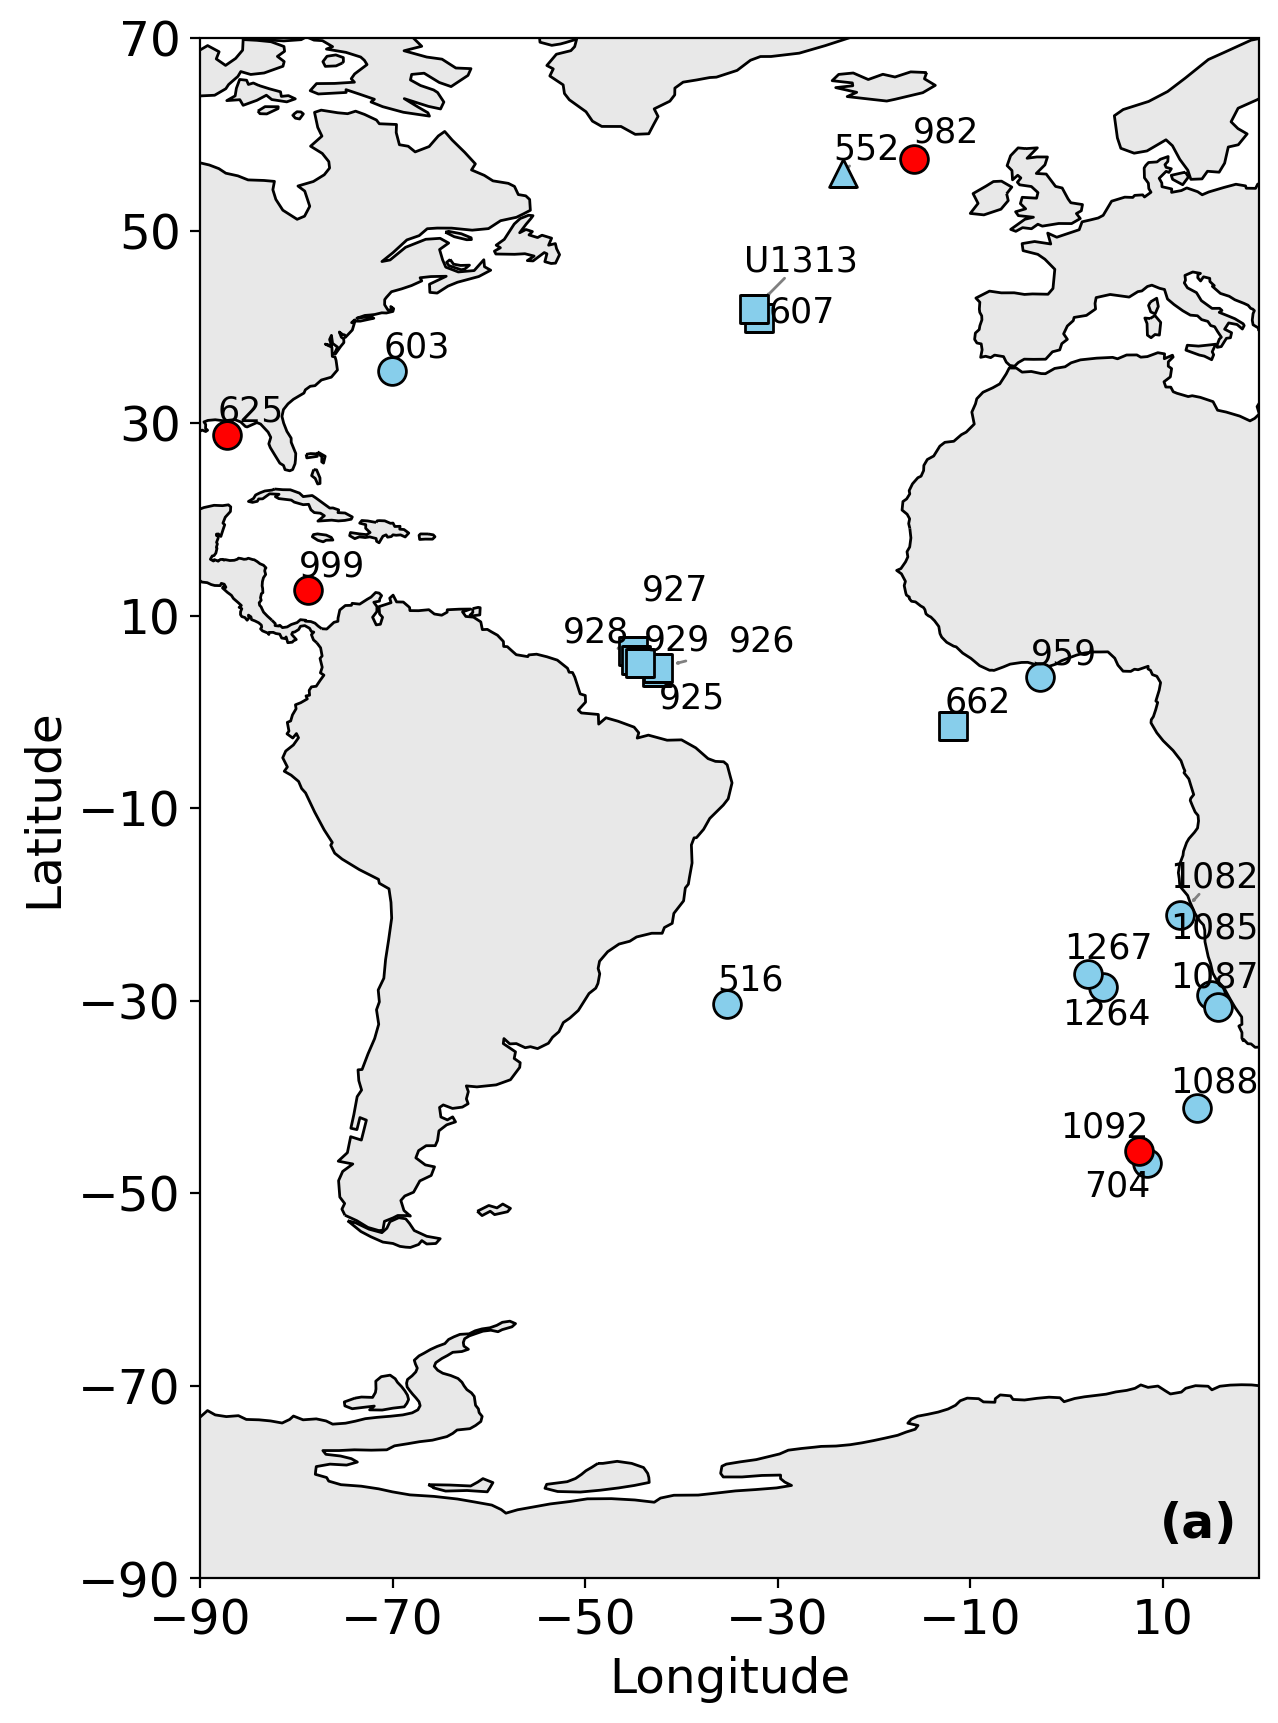

In [3]:
# Subplot A only (site map) — no red transect/box lines
# Assumes the prep from earlier cells already ran:
# plot_df, special_sites, marker_from_taxa, MAP_LABEL_ARROWPROPS,
# SITE_LABEL_FONTSIZE, PANEL_LABEL_FONTSIZE
#
# This figure is ~half the width of the combined figure above, so scale
# fonts by 1/2 so on-screen text matches panel A.

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from adjustText import adjust_text
import numpy as np

_font_scale = 0.5  # 12" standalone vs 24" combined figure
axis_fs = 35 * _font_scale
site_fs = SITE_LABEL_FONTSIZE * _font_scale
panel_fs = PANEL_LABEL_FONTSIZE * _font_scale

fig = plt.figure(figsize=(12, 10), dpi=200)
ax_map = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())

map_extent = [-90, 20, -90, 70]
map_lon_span = map_extent[1] - map_extent[0]
map_lat_span = map_extent[3] - map_extent[2]

# Plot site points only
for _, row in plot_df.iterrows():
    marker = marker_from_taxa(row.get("taxons", ""))
    site_name = str(row["Site name"])
    color = "red" if site_name in special_sites else "skyblue"
    ax_map.scatter(
        row["lon_off_map"], row["lat_off_map"],
        s=100, marker=marker, edgecolors="k", color=color, zorder=3,
        transform=ccrs.PlateCarree(),
    )

ax_map.set_extent(map_extent, crs=ccrs.PlateCarree())
ax_map.set_box_aspect(map_lat_span / map_lon_span)
ax_map.set_xticks(np.arange(-90, 30, 20), crs=ccrs.PlateCarree())
ax_map.set_yticks(np.arange(-90, 80, 20), crs=ccrs.PlateCarree())
ax_map.add_feature(cfeature.LAND, facecolor="lightgray", alpha=0.5, edgecolor="none", zorder=0)
ax_map.coastlines()
ax_map.set_xlabel("Longitude", fontsize=axis_fs)
ax_map.set_ylabel("Latitude", fontsize=axis_fs)
ax_map.tick_params(axis="both", labelsize=axis_fs)

# Site labels
map_texts = [
    ax_map.text(
        row["lon_off_map"], row["lat_off_map"], str(row["Site name"]),
        fontsize=site_fs, ha="center", color="black",
        transform=ccrs.PlateCarree(),
    )
    for _, row in plot_df.iterrows()
]

adjust_text(
    map_texts,
    expand=(1.15, 1.35),
    arrowprops=MAP_LABEL_ARROWPROPS,
    ax=ax_map,
)

# Panel label
ax_map.text(
    0.98, 0.02, "(a)",
    transform=ax_map.transAxes,
    ha="right", va="bottom",
    fontsize=panel_fs, fontweight="bold", zorder=20,
)

plt.show()
